# 🐘 Endangered Wildlife Detector
### Custom-training YOLO11 vs YOLO26 → keeping the best → flagging endangered species

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedsalmaan08/endangered-wildlife-yolo/blob/main/endangered_wildlife_detector.ipynb)

**What this notebook builds:** a model that looks at a photo, finds the wild animals in it, and tells you which
of them are **threatened with extinction**.

**How it works (two separate parts):**

| Part | Who does it | How |
|---|---|---|
| 1. *"What animal is this and where?"* | A **YOLO** object detector that we **fine-tune** on wildlife photos | Learned from labelled images |
| 2. *"Is that species endangered?"* | A small **lookup table** of IUCN Red List statuses | Looked up by species name |

> The model can't "see" that an animal is endangered. It only recognises the **species**.
> The endangered flag comes from the table in Step 7, which you can edit and extend.

**Steps**

1. Install & check the GPU
2. Settings
3. Get the dataset and look at it
4. Train YOLO11 *and* YOLO26 with identical settings
5. Test both on photos they have never seen
6. Compare speed and accuracy → **automatically pick the best model**
7. Add the endangered-species layer
8. Try it on photos (including your own upload)
9. Export and save

**Before you start:** `Runtime → Change runtime type → T4 GPU`. Then `Runtime → Run all`.
A full run takes roughly 30–60 minutes on a free T4 (an estimate, since it depends on Colab's load).
Set `QUICK_TEST = True` in Step 2 first if you only want to check that everything runs (a few minutes).

## 1 · Install and check the GPU
`ultralytics` is the library that contains both YOLO11 and YOLO26. `-U` upgrades it so it knows the newer YOLO26 weights.

In [1]:
!pip install -q -U ultralytics onnx onnxruntime onnxslim

import ultralytics
ultralytics.checks()   # prints Python / GPU / RAM info

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


## 2 · Settings
Everything you might want to change is in this one cell. Both models get **exactly the same settings**,
so the comparison is fair.

In [4]:
import os, random, json, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------ settings you can change ------------------------
QUICK_TEST = False    # True = tiny 3-epoch run just to check the notebook works
MODEL_SIZE = "n"      # n = nano (fast, fits free Colab). "s" is more accurate but slower
EPOCHS     = 3 if QUICK_TEST else 30    # passes over the training images
FRACTION   = 0.25 if QUICK_TEST else 1.0  # share of training images to use
IMGSZ      = 640      # images are resized to 640 x 640 pixels
BATCH      = 16       # images per training step
SEED       = 0        # fixed seed -> repeatable results
WORKERS    = min(8, os.cpu_count() or 2)  # CPU processes that load images for the GPU
N_BENCH    = 100      # how many test images to use for the speed test
TIE_MARGIN = 0.005    # if two models are within 0.5 mAP points, pick the faster one
DATA       = "african-wildlife.yaml"      # Ultralytics downloads this dataset automatically
# -------------------------------------------------------------------------

CANDIDATES = {                      # name -> COCO-pretrained starting weights
    f"YOLO11{MODEL_SIZE}": f"yolo11{MODEL_SIZE}.pt",
    f"YOLO26{MODEL_SIZE}": f"yolo26{MODEL_SIZE}.pt",
}
DEVICE   = 0 if torch.cuda.is_available() else "cpu"
ROOT     = Path("/content") if Path("/content").exists() else Path(".")
RUNS_DIR = ROOT / "runs"            # training outputs
OUT_DIR  = ROOT / "results"         # charts + tables we want to keep
OUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if DEVICE == "cpu":
    print("WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU (training on CPU takes hours).")
else:
    print("GPU:", torch.cuda.get_device_name(0))
print("Models to compare:", list(CANDIDATES), "| epochs:", EPOCHS, "| workers:", WORKERS)

GPU: Tesla T4
Models to compare: ['YOLO11n', 'YOLO26n'] | epochs: 30 | workers: 2


## 3 · The dataset
We use the **African Wildlife** dataset from Ultralytics: about 1,500 photos with boxes drawn around
**buffalo, elephant, rhino and zebra**. It downloads automatically (~100–200 MB).

It is split three ways:
- **train** – the images the model learns from
- **val** – used during training to track progress and keep the best checkpoint
- **test** – never touched during training, so it gives an honest final score

In [5]:
from ultralytics.data.utils import check_det_dataset

info = check_det_dataset(DATA)       # downloads + unzips on the first run
CLASS_NAMES = info["names"]          # {0: 'buffalo', 1: 'elephant', ...}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def as_dir(split):
    p = info.get(split)
    if isinstance(p, (list, tuple)):
        p = p[0] if p else None
    return Path(p) if p else None


def list_images(folder):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)


def label_dir(img_dir):
    """.../images/train  ->  .../labels/train"""
    parts = list(img_dir.parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    parts[i] = "labels"
    return Path(*parts)


# how many images and boxes per class in each split
rows = []
for split in ["train", "val", "test"]:
    folder = as_dir(split)
    if folder is None or not folder.exists():
        continue
    counts = np.zeros(len(CLASS_NAMES), dtype=int)
    for f in label_dir(folder).glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    rows.append({"split": split, "images": len(list_images(folder)),
                 **{CLASS_NAMES[i]: int(c) for i, c in enumerate(counts)}})
display(pd.DataFrame(rows))

# the held-out split used for the final scores (falls back to val if the dataset has no test split)
test_dir = as_dir("test")
EVAL_SPLIT = "test" if (test_dir is not None and test_dir.exists()) else "val"
print("Final scores will be measured on the", EVAL_SPLIT.upper(), "split")


WARNING ⚠️ Dataset 'african-wildlife.yaml' images not found, missing path '/content/datasets/african-wildlife/images/val'
Unzipping /content/datasets/african-wildlife.zip to /content/datasets/african-wildlife...: 100% ━━━━━━━━━━━━ 3018/3018 3.1Kfiles/s 1.0s
Dataset download success ✅ (1.7s), saved to /content/datasets



,split,images,buffalo,elephant,rhino,zebra
0,train,1052,399,558,399,575
1,val,225,89,91,85,114
2,test,227,66,99,75,135


Final scores will be measured on the TEST split


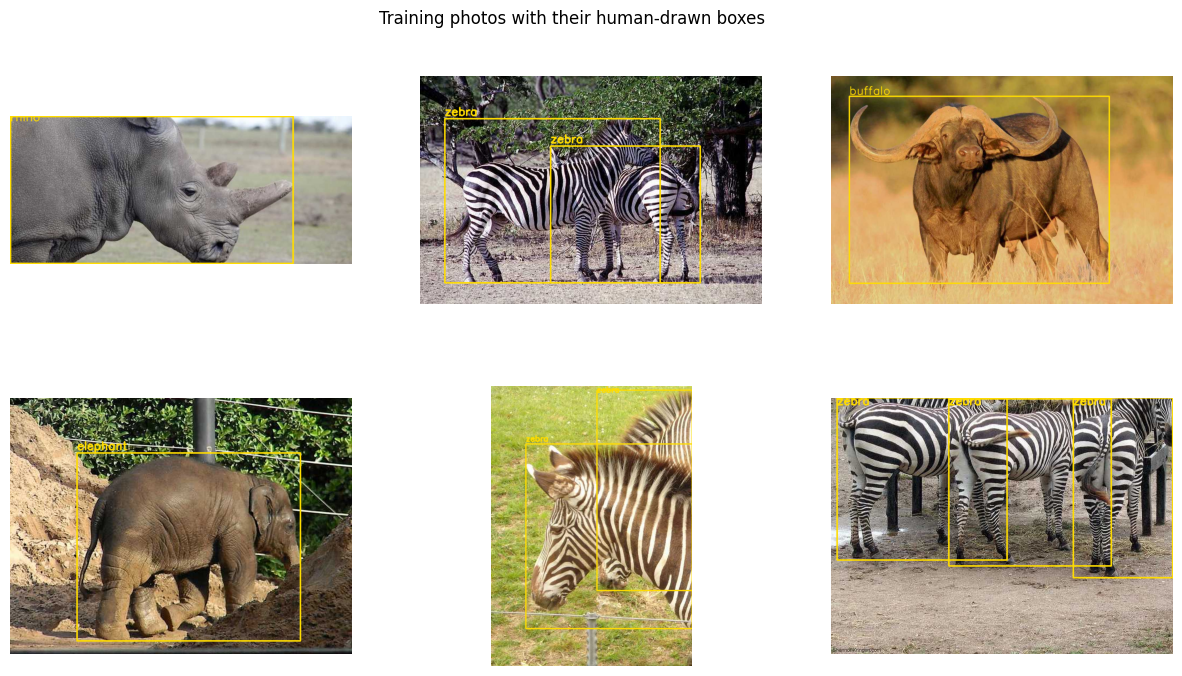

In [6]:
# a look at 6 random training photos with their human-drawn boxes
def draw_gt(img_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lf = label_dir(img_path.parent) / (img_path.stem + ".txt")
    if lf.exists():
        for line in lf.read_text().splitlines():
            c, x, y, bw, bh = line.split()[:5]
            x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
            p1, p2 = (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2))
            cv2.rectangle(img, p1, p2, (255, 220, 0), max(2, w // 300))
            cv2.putText(img, CLASS_NAMES[int(c)], (p1[0], max(p1[1] - 6, 14)),
                        cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 900), (255, 220, 0), 2)
    return img


sample = random.sample(list_images(as_dir("train")), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.ravel(), sample):
    ax.imshow(draw_gt(p)); ax.axis("off")
plt.suptitle("Training photos with their human-drawn boxes", y=0.93)
plt.show()

## 4 · Train both models
Both start from **COCO-pretrained** weights (a model that already knows everyday objects), and we **fine-tune** them
on wildlife. This is called *transfer learning*; it is much faster and needs far less data than training from scratch.

Everything is identical for the two runs (epochs, image size, batch size, seed, data). Everything else is left at the
Ultralytics defaults. Each run prints one progress line per epoch.

In [7]:
from ultralytics import YOLO

runs = {}    # everything we learn about each model is stored here
for name, weights in CANDIDATES.items():
    print(f"\n{'=' * 70}\nTraining {name}   (starting from {weights})\n{'=' * 70}")
    model = YOLO(weights)
    model.train(
        data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, fraction=FRACTION,
        seed=SEED, workers=WORKERS, device=DEVICE,
        project=str(RUNS_DIR), name=name, exist_ok=True,
    )
    save_dir = Path(model.trainer.save_dir)
    runs[name] = {"save_dir": save_dir, "best": save_dir / "weights" / "best.pt"}
    del model
    torch.cuda.empty_cache()

print("\nDone. Best checkpoints:", {k: str(v["best"]) for k, v in runs.items()})


Training YOLO11n   (starting from yolo11n.pt)
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n, nbs=64, nms=

## 5 · Test on photos the model has never seen
`best.pt` is the checkpoint with the highest validation score (not simply the last epoch).

Metrics (all between 0 and 1, **higher is better**):
- **mAP50-95**: the main accuracy score. How well the predicted boxes overlap the true boxes, averaged over strict and lenient overlap thresholds.
- **mAP50**: same idea with one lenient threshold, so it is always higher.
- **Precision**: of the animals the model reported, how many were right.
- **Recall**: of the animals that were really there, how many it found. *For conservation this matters a lot: a missed rhino is worse than a false alarm.*

In [8]:
def model_size(m):
    """(millions of parameters, GFLOPs) - a rough measure of how heavy a model is."""
    try:
        out = m.info(verbose=False)       # (layers, parameters, gradients, GFLOPs)
        return out[1] / 1e6, out[3]
    except Exception:
        return None, None


for name, r in runs.items():
    hist = pd.read_csv(r["save_dir"] / "results.csv")
    hist.columns = hist.columns.str.strip()
    r["history"] = hist
    r["train_min"] = hist["time"].iloc[-1] / 60          # training time in minutes
    r["best_epoch"] = int(hist.loc[hist["metrics/mAP50-95(B)"].idxmax(), "epoch"])

    m = YOLO(r["best"])
    r["params_m"], r["gflops"] = model_size(m)
    res = m.val(data=DATA, split=EVAL_SPLIT, imgsz=IMGSZ, batch=BATCH,
                device=DEVICE, plots=False, verbose=False)
    r.update(precision=float(res.box.mp), recall=float(res.box.mr),
             map50=float(res.box.map50), map5095=float(res.box.map),
             per_class=np.array(res.box.maps))
    print(f"{name}: mAP50-95={r['map5095']:.3f}  mAP50={r['map50']:.3f}  "
          f"precision={r['precision']:.3f}  recall={r['recall']:.3f}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1729.3±790.2 MB/s, size: 53.5 KB)
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.1Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.4it/s 2.4s
                   all        227        375      0.969      0.929      0.971      0.827
Speed: 0.7ms preprocess, 5.1ms inference, 0.0ms loss, 1.1ms postprocess per image
YOLO11n: mAP50-95=0.827  mAP50=0.971  precision=0.969  recall=0.929
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLO

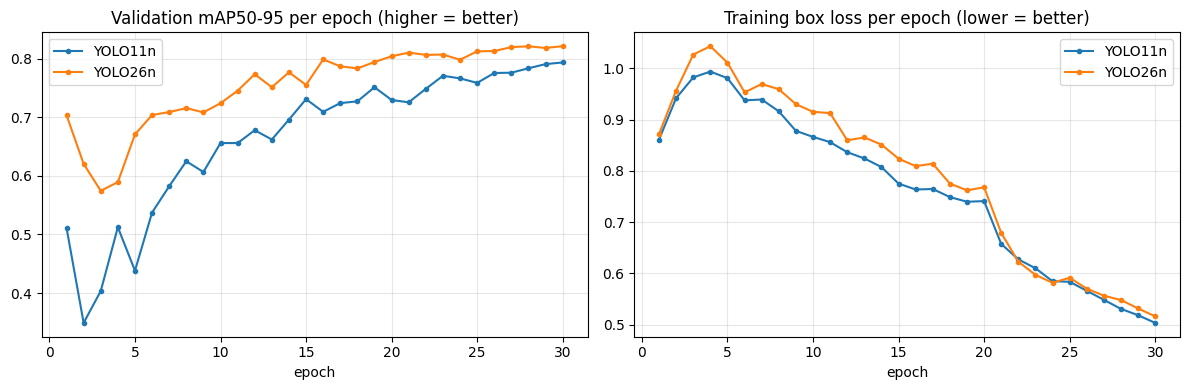

mAP50-95 per species on the test split:


,YOLO11n,YOLO26n
buffalo,0.850,0.867
elephant,0.803,0.817
rhino,0.882,0.902
zebra,0.771,0.803


In [9]:
# learning curves: did training behave, and did one model learn faster?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in runs.items():
    h = r["history"]
    axes[0].plot(h["epoch"], h["metrics/mAP50-95(B)"], marker="o", ms=3, label=name)
    loss_col = next((c for c in h.columns if c.startswith("train/") and "box" in c), None)
    if loss_col:                                  # the loss column name can differ between model families
        axes[1].plot(h["epoch"], h[loss_col], marker="o", ms=3, label=name)
axes[0].set_title("Validation mAP50-95 per epoch (higher = better)")
axes[1].set_title("Training box loss per epoch (lower = better)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# which species is hardest for each model?
per_class = pd.DataFrame({n: r["per_class"] for n, r in runs.items()},
                         index=[CLASS_NAMES[i] for i in range(len(CLASS_NAMES))])
print("mAP50-95 per species on the", EVAL_SPLIT, "split:")
display(per_class.round(3))

## 6 · Speed test and picking the winner
Accuracy is only half the story. A model that runs on a cheap camera-trap computer needs to be **fast on a CPU**;
one on a cloud server can use a GPU. We measure both, using **one image at a time**:

- **CPU**: the model exported to **ONNX** (a portable format) and run with `onnxruntime`.
- **GPU**: the normal PyTorch `.pt` model.

YOLO26 is **NMS-free** (it does not need the "remove duplicate boxes" clean-up step). The export below uses that
NMS-free head for YOLO26 and standard NMS for YOLO11, so watch the `post` (post-processing) column.
Times are in milliseconds per image (median over the test images).

In [10]:
bench_imgs = [str(p) for p in list_images(as_dir(EVAL_SPLIT))[:N_BENCH]]
print(f"Speed test on {len(bench_imgs)} images")


def bench(weights, device, paths, warmup=10):
    """Median pre-process / inference / post-process time (ms) for one-image-at-a-time prediction."""
    m = YOLO(str(weights), task="detect")
    for p in paths[:warmup]:                      # warm-up runs are not counted
        m.predict(p, imgsz=IMGSZ, device=device, verbose=False)
    pre, inf, post = [], [], []
    for p in paths:
        s = m.predict(p, imgsz=IMGSZ, device=device, verbose=False)[0].speed
        pre.append(s["preprocess"]); inf.append(s["inference"]); post.append(s["postprocess"])
    pre, inf, post = (float(np.median(x)) for x in (pre, inf, post))
    return {"pre": pre, "inf": inf, "post": post, "total": pre + inf + post}


for name, r in runs.items():
    m = YOLO(r["best"])
    # Only YOLO26-style heads have a "one-to-one" branch, which is what makes them NMS-free.
    nms_free = getattr(m.model.model[-1], "one2one_cv2", None) is not None
    # nms=False -> export the NMS-free head. YOLO11 has none, so it keeps standard NMS.
    onnx_path = Path(m.export(format="onnx", imgsz=IMGSZ, simplify=True,
                              **({"nms": False} if nms_free else {})))
    r["onnx"], r["nms_free"] = onnx_path, nms_free
    r["onnx_mb"] = onnx_path.stat().st_size / 1e6
    r["cpu"] = bench(onnx_path, "cpu", bench_imgs)
    r["gpu"] = bench(r["best"], 0, bench_imgs) if torch.cuda.is_available() else None
    print(f"{name} (NMS-free export: {nms_free}): CPU {r['cpu']['total']:.1f} ms/img" +
          (f" | GPU {r['gpu']['total']:.1f} ms/img" if r["gpu"] else ""))

Speed test on 100 images
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/runs/YOLO11n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.5s, saved as '/content/runs/YOLO11n/weights/best.onnx' (10.2 MB)

Export complete (1.9s)
Results saved to /content/runs/YOLO11n/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/YOLO11n/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/YOLO11n/weights/best.onnx imgsz=640 data=/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/dat

,params (M),GFLOPs,train time (min),best epoch,precision,recall,mAP50,mAP50-95,ONNX size (MB),CPU pre (ms),CPU infer (ms),CPU post (ms),CPU total (ms),GPU total (ms)
YOLO11n,NaN,NaN,9.017,30.0,0.969,0.929,0.971,0.827,10.666,4.336,85.375,0.987,90.698,11.149
YOLO26n,NaN,NaN,9.804,30.0,0.976,0.936,0.983,0.847,9.867,4.318,70.371,0.446,75.135,15.522


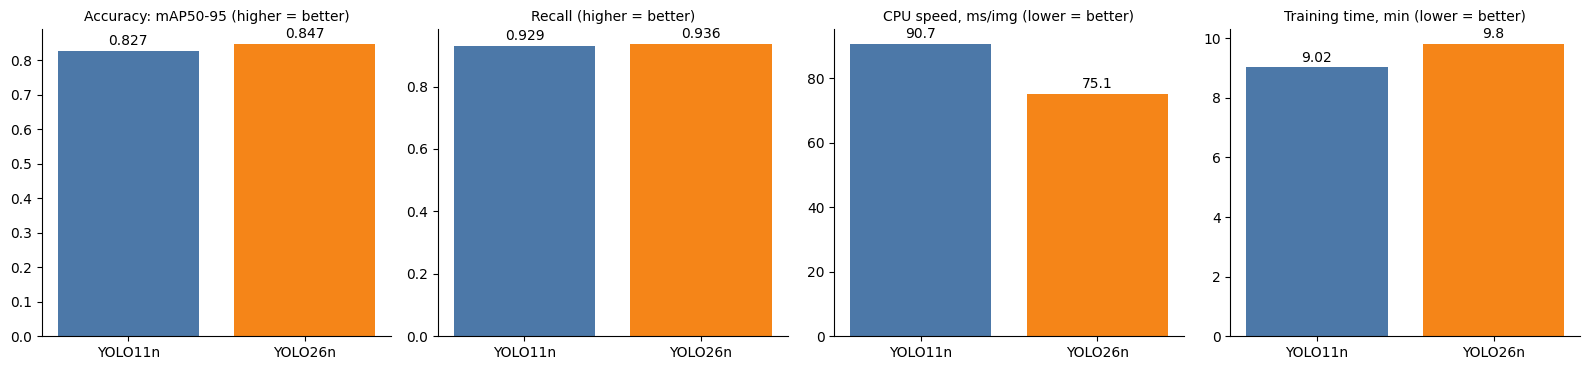

In [11]:
# one summary table
df = pd.DataFrame({
    name: {
        "params (M)": r["params_m"], "GFLOPs": r["gflops"],
        "train time (min)": r["train_min"], "best epoch": r["best_epoch"],
        "precision": r["precision"], "recall": r["recall"],
        "mAP50": r["map50"], "mAP50-95": r["map5095"],
        "ONNX size (MB)": r["onnx_mb"],
        "CPU pre (ms)": r["cpu"]["pre"], "CPU infer (ms)": r["cpu"]["inf"],
        "CPU post (ms)": r["cpu"]["post"], "CPU total (ms)": r["cpu"]["total"],
        "GPU total (ms)": r["gpu"]["total"] if r["gpu"] else np.nan,
    } for name, r in runs.items()
}).T
display(df.round(3))
df.round(4).to_csv(OUT_DIR / "comparison.csv")

# charts
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
colors = ["#4C78A8", "#F58518"]
for ax, (col, title) in zip(axes, [("mAP50-95", "Accuracy: mAP50-95 (higher = better)"),
                                   ("recall", "Recall (higher = better)"),
                                   ("CPU total (ms)", "CPU speed, ms/img (lower = better)"),
                                   ("train time (min)", "Training time, min (lower = better)")]):
    bars = ax.bar(df.index, df[col], color=colors[:len(df)])
    ax.bar_label(bars, fmt="%.3g", padding=2)
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Automatic pick: highest test mAP50-95; if two models are within TIE_MARGIN, take the faster one on CPU.
top = df["mAP50-95"].max()
close = df[df["mAP50-95"] >= top - TIE_MARGIN]
BEST_NAME = close["CPU total (ms)"].idxmin()

print(f"Best mAP50-95: {top:.3f}.  Models within {TIE_MARGIN} of that: {list(close.index)}")
print(f"\n>>> WINNER: {BEST_NAME} <<<")
best_model = YOLO(runs[BEST_NAME]["best"])

# --- how do our measurements compare with the claims in the original memo? ---
a, b = f"YOLO11{MODEL_SIZE}", f"YOLO26{MODEL_SIZE}"
saved = lambda old, new: (old - new) / old * 100       # % reduction when going YOLO11 -> YOLO26
print("\nMemo claim vs what we measured (YOLO11 -> YOLO26):")
print(f"  Training time : memo expected ~31-40% less | measured {saved(df.loc[a,'train time (min)'], df.loc[b,'train time (min)']):+.0f}% less")
print(f"  CPU inference : Ultralytics claims up to 43% faster | measured {saved(df.loc[a,'CPU total (ms)'], df.loc[b,'CPU total (ms)']):+.0f}% faster")
print(f"  Post-process  : (NMS-free) {df.loc[a,'CPU post (ms)']:.2f} ms -> {df.loc[b,'CPU post (ms)']:.2f} ms")
print(f"  Accuracy      : mAP50-95 {df.loc[a,'mAP50-95']:.3f} -> {df.loc[b,'mAP50-95']:.3f} ({df.loc[b,'mAP50-95'] - df.loc[a,'mAP50-95']:+.3f})")

Best mAP50-95: 0.847.  Models within 0.005 of that: ['YOLO26n']

>>> WINNER: YOLO26n <<<

Memo claim vs what we measured (YOLO11 -> YOLO26):
  Training time : memo expected ~31-40% less | measured -9% less
  CPU inference : Ultralytics claims up to 43% faster | measured +17% faster
  Post-process  : (NMS-free) 0.99 ms -> 0.45 ms
  Accuracy      : mAP50-95 0.827 -> 0.847 (+0.021)


> **Read these numbers with care.** This is a small *nano* model on a 4-class dataset, trained once with a single seed.
> A gap of a point or two in mAP can be noise: re-run with another `SEED` before calling a winner.
> The original memo was about the large `x` model on 120 classes, which can behave differently.

In [14]:
# PATCH: fill params/GFLOPs (were NaN) and re-print the memo comparison with clearer wording
def model_size(m):
    out = m.info()                  # prints a one-line summary; info(verbose=False) returns None
    return out[1] / 1e6, out[3]     # (millions of parameters, GFLOPs)

for name, r in runs.items():
    r["params_m"], r["gflops"] = model_size(YOLO(r["best"]))
    df.loc[name, "params (M)"] = r["params_m"]
    df.loc[name, "GFLOPs"] = r["gflops"]
df["GPU infer (ms)"] = [runs[n]["gpu"]["inf"] if runs[n]["gpu"] else np.nan for n in df.index]

display(df.round(3))
df.round(4).to_csv(OUT_DIR / "comparison.csv")

a, b = f"YOLO11{MODEL_SIZE}", f"YOLO26{MODEL_SIZE}"
change = lambda col: (df.loc[b, col] - df.loc[a, col]) / df.loc[a, col] * 100   # % change, YOLO11 -> YOLO26
words = lambda pct, down, up: f"{abs(pct):.0f}% {down if pct < 0 else up}"
print("\nMemo claim vs what we measured (YOLO11 -> YOLO26):")
print(f"  Training time : memo expected ~31-40% less          | measured {words(change('train time (min)'), 'less', 'MORE')}")
print(f"  CPU latency   : Ultralytics claims up to 43% faster | measured {words(change('CPU total (ms)'), 'faster', 'SLOWER')}")
print(f"  GPU latency   : (no memo claim)                     | measured {words(change('GPU total (ms)'), 'faster', 'SLOWER')}")
print(f"  Post-process  : (NMS-free) {df.loc[a,'CPU post (ms)']:.2f} ms -> {df.loc[b,'CPU post (ms)']:.2f} ms")
print(f"  Accuracy      : mAP50-95 {df.loc[a,'mAP50-95']:.3f} -> {df.loc[b,'mAP50-95']:.3f} ({df.loc[b,'mAP50-95'] - df.loc[a,'mAP50-95']:+.3f})")

YOLO11n summary: 182 layers, 2,605,612 parameters, 0 gradients, 6.6 GFLOPs
YOLO26n summary: 261 layers, 2,535,344 parameters, 0 gradients, 6.0 GFLOPs


,params (M),GFLOPs,train time (min),best epoch,precision,recall,mAP50,mAP50-95,ONNX size (MB),CPU pre (ms),CPU infer (ms),CPU post (ms),CPU total (ms),GPU total (ms),GPU infer (ms)
YOLO11n,2.606,6.571,9.017,30.0,0.969,0.929,0.971,0.827,10.666,4.336,85.375,0.987,90.698,11.149,8.703
YOLO26n,2.535,6.035,9.804,30.0,0.976,0.936,0.983,0.847,9.867,4.318,70.371,0.446,75.135,15.522,12.592



Memo claim vs what we measured (YOLO11 -> YOLO26):
  Training time : memo expected ~31-40% less          | measured 9% MORE
  CPU latency   : Ultralytics claims up to 43% faster | measured 17% faster
  GPU latency   : (no memo claim)                     | measured 39% SLOWER
  Post-process  : (NMS-free) 0.99 ms -> 0.45 ms
  Accuracy      : mAP50-95 0.827 -> 0.847 (+0.021)


## 7 · The endangered-species layer
Now the second half of the project. The detector outputs a **species name**; this table maps each name to its
**IUCN Red List** category:

| Code | Meaning | Treated here as |
|---|---|---|
| `CR` | Critically Endangered | 🔴 **endangered** |
| `EN` | Endangered | 🔴 **endangered** |
| `VU` | Vulnerable | 🟠 threatened |
| `NT` | Near Threatened | 🔵 watch |
| `LC` | Least Concern | 🟢 ok |
| `NE` | not in our table | ⚪ unknown |

> ⚠️ Statuses change when the IUCN reassesses a species. The values below were checked against IUCN-related sources
> in October 2026 and carry the assessment year. **Always confirm on [iucnredlist.org](https://www.iucnredlist.org/)
> before relying on them**, and edit the table whenever it changes.
>
> Note that the dataset's classes are broader than a species ("rhino" mixes black and white rhinos, which have
> different statuses), so for those we show the **most severe** status. That is the safe direction for a conservation alert.

In [15]:
IUCN_LEVELS = {"CR": "Critically Endangered", "EN": "Endangered", "VU": "Vulnerable",
               "NT": "Near Threatened", "LC": "Least Concern", "NE": "Not in table"}
ENDANGERED = {"CR", "EN"}               # the red-alert categories
THREATENED = {"CR", "EN", "VU"}         # IUCN's official "threatened" group

# key = the class name used by the dataset. ADD YOUR OWN SPECIES HERE if you use another dataset.
SPECIES = {
    "elephant": {"common": "African savanna elephant", "scientific": "Loxodonta africana",
                 "iucn": "EN", "year": 2021,
                 "note": "African forest elephant (L. cyclotis) is Critically Endangered."},
    "rhino":    {"common": "Rhinoceros (black / white)", "scientific": "Diceros bicornis / Ceratotherium simum",
                 "iucn": "CR", "year": 2020,
                 "note": "Black rhino is CR; white rhino is NT (northern subspecies CR). Worst case shown."},
    "zebra":    {"common": "Plains zebra", "scientific": "Equus quagga",
                 "iucn": "NT", "year": 2016,
                 "note": "Other zebras differ (e.g. Grevy's zebra is Endangered)."},
    "buffalo":  {"common": "African buffalo", "scientific": "Syncerus caffer",
                 "iucn": "NT", "year": 2019,
                 "note": "Listed as Near Threatened globally."},
}


def status_of(class_name):
    return SPECIES.get(class_name.lower(),
                       {"common": class_name, "scientific": "?", "iucn": "NE", "year": None, "note": ""})


def alert_level(code):
    if code in ENDANGERED: return "ALERT"
    if code in THREATENED or code == "NT": return "WATCH"
    return "OK" if code == "LC" else "?"


table = pd.DataFrame([{**{"class": n}, **status_of(n),
                       "endangered?": status_of(n)["iucn"] in ENDANGERED,
                       "threatened?": status_of(n)["iucn"] in THREATENED}
                      for n in CLASS_NAMES.values()]).set_index("class")
display(table[["common", "scientific", "iucn", "year", "endangered?", "threatened?", "note"]])

missing = [n for n in CLASS_NAMES.values() if n.lower() not in SPECIES]
if missing:
    print("These classes are not in SPECIES yet (shown as 'NE'):", missing)

,common,scientific,iucn,year,endangered?,threatened?,note
class,,,,,,,
buffalo,African buffalo,Syncerus caffer,NT,2019,False,False,Listed as Near Threatened globally.
elephant,African savanna elephant,Loxodonta africana,EN,2021,True,True,African forest elephant (L. cyclotis) is Criti...
rhino,Rhinoceros (black / white),Diceros bicornis / Ceratotherium simum,CR,2020,True,True,Black rhino is CR; white rhino is NT (northern...
zebra,Plains zebra,Equus quagga,NT,2016,False,False,Other zebras differ (e.g. Grevy's zebra is End...


## 8 · Try it on photos
`detect_and_flag` runs the winning model and draws each box in a colour that shows the species' IUCN status
(red = endangered, orange = vulnerable, blue = near threatened, green = least concern).

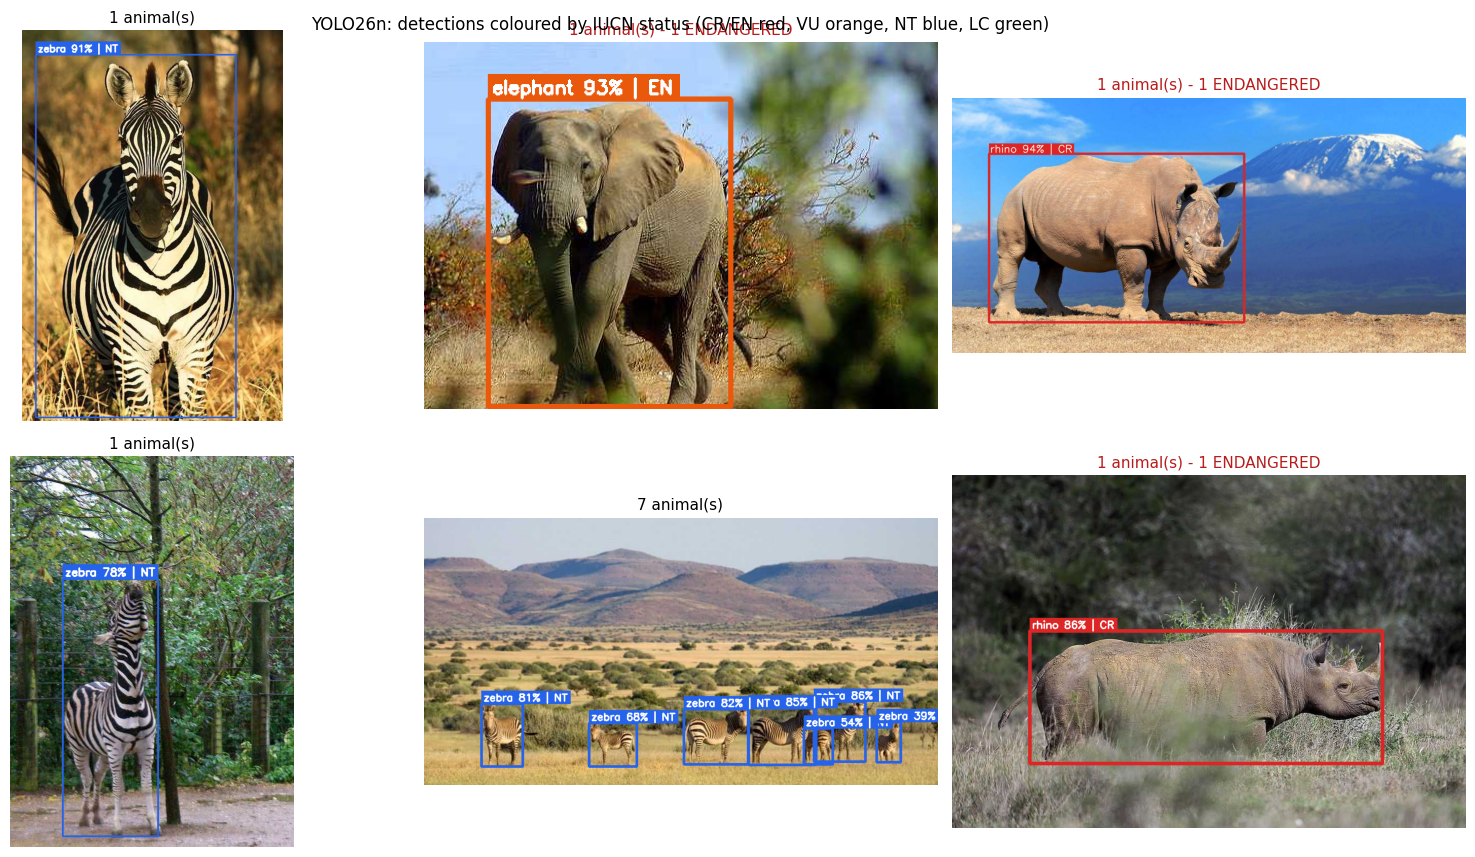

Report for the first photo:
  [WATCH] 1 x zebra     -> Near Threatened (NT)


In [16]:
BOX_COLORS = {"CR": (220, 38, 38), "EN": (234, 88, 12), "VU": (202, 138, 4),
              "NT": (37, 99, 235), "LC": (22, 163, 74), "NE": (107, 114, 128)}   # RGB


def detect_and_flag(model, image_path, conf=0.35):
    """Detect animals, draw colour-coded boxes, return (image, list of detections)."""
    r = model.predict(image_path, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    img = cv2.cvtColor(r.orig_img, cv2.COLOR_BGR2RGB)
    scale = max(img.shape[:2]) / 900
    found = []
    for box in r.boxes:
        species, score = r.names[int(box.cls)], float(box.conf)
        x1, y1, x2, y2 = (int(v) for v in box.xyxy[0].tolist())
        s = status_of(species)
        color = BOX_COLORS[s["iucn"]]
        thick = max(2, int(3 * scale)) + (2 if s["iucn"] in ENDANGERED else 0)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, thick)
        label = f"{species} {score:.0%} | {s['iucn']}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6 * max(scale, 1), 2)
        cv2.rectangle(img, (x1, max(y1 - th - 10, 0)), (x1 + tw + 8, max(y1, th + 10)), color, -1)
        cv2.putText(img, label, (x1 + 4, max(y1 - 5, th + 4)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6 * max(scale, 1), (255, 255, 255), 2)
        found.append({"species": species, "confidence": score, "iucn": s["iucn"]})
    return img, found


def report(found):
    """Print a short conservation summary for one photo."""
    if not found:
        print("  No animals detected."); return
    for sp, n in pd.Series([f["species"] for f in found]).value_counts().items():
        code_ = status_of(sp)["iucn"]
        print(f"  [{alert_level(code_):5}] {n} x {sp:9} -> {IUCN_LEVELS[code_]} ({code_})")


# a grid of random held-out photos
pics = random.sample(list_images(as_dir(EVAL_SPLIT)), min(6, len(list_images(as_dir(EVAL_SPLIT)))))
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, p in zip(axes.ravel(), pics):
    img, found = detect_and_flag(best_model, str(p))
    ax.imshow(img); ax.axis("off")
    n_alert = sum(f["iucn"] in ENDANGERED for f in found)
    ax.set_title(f"{len(found)} animal(s)" + (f" - {n_alert} ENDANGERED" if n_alert else ""),
                 color="#b91c1c" if n_alert else "black", fontsize=11)
plt.suptitle(f"{BEST_NAME}: detections coloured by IUCN status (CR/EN red, VU orange, NT blue, LC green)", y=0.94)
plt.tight_layout()
plt.savefig(OUT_DIR / "predictions.png", dpi=130, bbox_inches="tight")
plt.show()

print("Report for the first photo:")
report(detect_and_flag(best_model, str(pics[0]))[1])

### Your own photo
Run the next cell and pick an image from your computer (a safari photo, a zoo photo, anything with the four species).
Heads-up: the model only knows **buffalo, elephant, rhino and zebra**. It will not recognise a lion or a tiger.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    uploaded = {}
    print("Not in Colab. Call detect_and_flag(best_model, 'your_image.jpg') directly.")

for fn in uploaded:
    img, found = detect_and_flag(best_model, fn)
    plt.figure(figsize=(10, 7)); plt.imshow(img); plt.axis("off"); plt.title(fn); plt.show()
    report(found)

## 9 · Export and save
We package the winning model (`best.pt`, plus an ONNX version for CPU / edge devices), the species table and the
metrics into one zip. **Colab wipes its disk when the session ends**, so download this (or copy it to Google Drive).

In [17]:
FINAL = ROOT / "endangered_wildlife_detector"
FINAL.mkdir(parents=True, exist_ok=True)

shutil.copy(runs[BEST_NAME]["best"], FINAL / "best.pt")
shutil.copy(runs[BEST_NAME]["onnx"], FINAL / "best.onnx")
(FINAL / "species_status.json").write_text(json.dumps(SPECIES, indent=2))
(FINAL / "metrics.json").write_text(json.dumps(
    {"winner": BEST_NAME, "eval_split": EVAL_SPLIT, "epochs": EPOCHS,
     "comparison": json.loads(df.round(4).to_json(orient="index"))}, indent=2))
for f in OUT_DIR.glob("*"):
    shutil.copy(f, FINAL / f.name)

zip_path = shutil.make_archive(str(ROOT / "endangered_wildlife_detector"), "zip", FINAL)
print("Saved:", zip_path)
print("Contents:", sorted(p.name for p in FINAL.iterdir()))

try:
    from google.colab import files
    files.download(zip_path)          # downloads to your computer
    # Or keep it on Google Drive instead:
    # from google.colab import drive; drive.mount("/content/drive")
    # shutil.copy(zip_path, "/content/drive/MyDrive/")
except ImportError:
    pass

Saved: /content/endangered_wildlife_detector.zip
Contents: ['best.onnx', 'best.pt', 'comparison.csv', 'comparison.png', 'learning_curves.png', 'metrics.json', 'predictions.png', 'species_status.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Use the saved model later (no re-training needed)
```python
from ultralytics import YOLO
model = YOLO("best.pt")                      # or "best.onnx"
results = model.predict("my_photo.jpg", conf=0.35)
```
Then look each detected class name up in `species_status.json`.

## What this project shows and what it doesn't
- ✅ A model fine-tuned on **your own data** can be built in under an hour on a free GPU.
- ✅ "Endangered" is handled as a **separate, editable knowledge layer**, so it can be corrected without re-training.
- ⚠️ Only **4 species** (African savanna animals). A real conservation tool needs many more species, and more varied photos
  (night / infrared camera-trap images, partial views, herds, different regions).
- ⚠️ Class-level labels hide species-level differences (e.g. black vs white rhino). Distinguishing them needs a dataset labelled that finely.
- ⚠️ One run, one seed. Repeat with a few seeds before trusting small differences between models.

## Ideas to take it further
1. Swap `DATA` for a bigger dataset (Roboflow Universe, Open Images, iNaturalist, LILA camera-trap sets) and add the new species to `SPECIES`.
2. Train the larger `MODEL_SIZE = "s"` or `"m"` models.
3. Run on video and count animals per frame; log alerts to a CSV.
4. Wrap it in a small Gradio / Streamlit web app.

**Licences:** Ultralytics YOLO code and weights are AGPL-3.0 (or a paid Enterprise licence); check the dataset's licence on its Ultralytics page before commercial use.